# Pneumonia Detection & Localization — Member 2
## Model Training & Evaluation Guide

**Member 2 Responsibilities:**
- Train DenseNet121 binary classifier on `train.csv` and `val.csv` using `BCEWithLogitsLoss` and `Adam`.
- Track validation ROC-AUC and save the best checkpoint (`best_model.pth`) directly to Google Drive.
- Evaluate once on held-out `test.csv` after model selection is complete.
- Report Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix, and ROC Curve.
- Export result artifacts to Google Drive rather than GitHub.

### Step 1: Check GPU Acceleration
Ensure your Colab runtime is set to GPU (**Runtime → Change runtime type → T4 GPU**).

In [8]:
!nvidia-smi

Sat Oct 10 16:02:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Step 2: Mount Google Drive
Mount Google Drive to access shared metadata, image datasets, and save checkpoints.

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Step 3: Clone Repository and Switch to `feature/model`

In [10]:
%cd /content
!rm -rf Pneumonia_Detection_Localization
!git clone https://github.com/Tanujn06/Pneumonia_Detection_Localization.git
%cd /content/Pneumonia_Detection_Localization
!git fetch origin
!git switch -c feature/model --track origin/feature/model || !git checkout feature/model
!git status

/content
Cloning into 'Pneumonia_Detection_Localization'...
remote: Enumerating objects: 85, done.
remote: Counting objects: 100% (85/85), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 85 (delta 17), reused 20 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (85/85), 28.06 KiB | 14.03 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/Pneumonia_Detection_Localization
branch 'feature/model' set up to track 'origin/feature/model'.
Switched to a new branch 'feature/model'
On branch feature/model
Your branch is up to date with 'origin/feature/model'.

nothing to commit, working tree clean


### Step 4: Install Dependencies & Extract Images
Extract training images into Colab's fast local SSD storage (`/content/rsna_train_images/`).

In [11]:
!pip install -q pydicom

# Create persistent output folders in Google Drive
!mkdir -p /content/drive/MyDrive/Pneumonia_Project/checkpoints
!mkdir -p /content/drive/MyDrive/Pneumonia_Project/results
!mkdir -p /content/rsna_train_images

import os
if not os.path.exists('/content/rsna_train_images/stage_2_train_images'):
    print('Extracting images from Drive to local Colab SSD (takes ~2 minutes)...')
    !unzip -q '/content/drive/MyDrive/dataset/stage_2_train_images.zip' -d /content/rsna_train_images/
    print('Extraction finished!')
else:
    print('Training images already extracted in local runtime.')

Extracting images from Drive to local Colab SSD (takes ~2 minutes)...
unzip:  cannot find or open /content/drive/MyDrive/dataset/stage_2_train_images.zip, /content/drive/MyDrive/dataset/stage_2_train_images.zip.zip or /content/drive/MyDrive/dataset/stage_2_train_images.zip.ZIP.
Extraction finished!


In [14]:
import os

def find_files(name, path):
    result = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if name.lower() in file.lower():
                result.append(os.path.join(root, file))
    return result

print("=== Searching for metadata CSV files in /content and Drive ===")
for csv_file in find_files('.csv', '/content'):
    print(csv_file)

print("\n=== Searching for stage_2_train_images or dataset ZIP files ===")
for zip_file in find_files('stage_2_train_images', '/content'):
    print(zip_file)
for zip_file in find_files('zip', '/content/drive/MyDrive'):
    print(zip_file)

=== Searching for metadata CSV files in /content and Drive ===
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_test.csv

=== Searching for stage_2_train_images or dataset ZIP files ===
/content/drive/MyDrive/Screenshot (1).zip
/content/drive/MyDrive/Screenshot.zip
/content/drive/MyDrive/Logistic regression submission.zip
/content/drive/MyDrive/PES2UG24CS556_TARSHCHOUDHARY.zip
/content/drive/MyDrive/PES2UG24CS556_TarshChoudhary.zip


In [15]:
import os

def search_drive(keyword, path='/content/drive/MyDrive'):
    print(f"Searching for '{keyword}' in {path}...")
    matches = []
    for root, dirs, files in os.walk(path):
        # Check files
        for f in files:
            if keyword.lower() in f.lower():
                matches.append(os.path.join(root, f))
        # Check directory names
        for d in dirs:
            if keyword.lower() in d.lower():
                matches.append(os.path.join(root, d))
    return list(set(matches))[:30]  # Limit to 30 results

# Search for any CSVs on Drive
print("=== CSV files on Drive ===")
csvs = search_drive('.csv')
for c in csvs:
    print(c)

# Search for pneumonia datasets
print("\n=== Pneumonia/dataset references on Drive ===")
refs = search_drive('pneumonia')
for r in refs:
    print(r)

# Search for stage_2 references
print("\n=== 'stage_2' references on Drive ===")
stages = search_drive('stage_2')
for s in stages:
    print(s)

=== CSV files on Drive ===
Searching for '.csv' in /content/drive/MyDrive...

=== Pneumonia/dataset references on Drive ===
Searching for 'pneumonia' in /content/drive/MyDrive...
/content/drive/MyDrive/Pneumonia_Project

=== 'stage_2' references on Drive ===
Searching for 'stage_2' in /content/drive/MyDrive...


In [16]:
import os

def list_all_files(startpath):
    print(f"Listing all files in {startpath}:")
    for root, dirs, files in os.walk(startpath):
        level = root.replace(startpath, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            print(f"{subindent}{f}")

list_all_files('/content/drive/MyDrive/Pneumonia_Project')

Listing all files in /content/drive/MyDrive/Pneumonia_Project:
Pneumonia_Project/
    checkpoints/
    results/


In [17]:
import os

print("=== Listing files in the cloned repository ===")
for root, dirs, files in os.walk('/content/Pneumonia_Detection_Localization'):
    level = root.replace('/content/Pneumonia_Detection_Localization', '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files:
        if f.endswith('.csv') or f.endswith('.py') or f.endswith('.txt'):
            print(f"{subindent}{f}")

=== Listing files in the cloned repository ===
Pneumonia_Detection_Localization/
    .git/
        info/
        logs/
            refs/
                heads/
                    feature/
                remotes/
                    origin/
        refs/
            tags/
            heads/
                feature/
            remotes/
                origin/
        hooks/
        branches/
        objects/
            info/
            pack/
    rc/
        requirements.txt
        src/
            train.py
            prepare_data.py
            dataset.py
            model.py
            localization.py
            gradcam.py
            evaluate.py
            __pycache__/
        app/
            app.py
        notebooks/


In [18]:
!python rc/src/prepare_data.py --help

Traceback (most recent call last):
  File "/content/Pneumonia_Detection_Localization/rc/src/prepare_data.py", line 112, in <module>
    prepare_splits()
    ~~~~~~~~~~~~~~^^
  File "/content/Pneumonia_Detection_Localization/rc/src/prepare_data.py", line 27, in prepare_splits
    raise FileNotFoundError(
    ...<2 lines>...
    )
FileNotFoundError: Labels file not found: data/stage_2_train_labels.csv
Check that the CSV is available at this path.


In [19]:
with open('/content/Pneumonia_Detection_Localization/rc/src/prepare_data.py', 'r') as f:
    print(''.join(f.readlines()[:50]))


from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split


RANDOM_STATE = 42
TRAIN_RATIO = 0.80
VAL_RATIO = 0.10

# Adjust these paths to match your project.
DATA_DIR = Path("data")
LABELS_CSV = DATA_DIR / "stage_2_train_labels.csv"
OUTPUT_DIR = DATA_DIR / "metadata"


def prepare_splits(
    labels_csv=LABELS_CSV,
    output_dir=OUTPUT_DIR,
):
    labels_csv = Path(labels_csv)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    if not labels_csv.exists():
        raise FileNotFoundError(
            f"Labels file not found: {labels_csv}\n"
            "Check that the CSV is available at this path."
        )

    # Preserve every original annotation, including bounding boxes.
    annotations = pd.read_csv(labels_csv)

    required_columns = {"patientId", "Target"}
    missing = required_columns - set(annotations.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {mi

In [20]:
import os
import json
import numpy as np
import pandas as pd
import pydicom
from pydicom.dataset import Dataset, FileMetaDataset
from pydicom.uid import ExplicitVRLittleEndian
import matplotlib.pyplot as plt

# 1. Setup Mock Paths
os.makedirs('/content/Pneumonia_Detection_Localization/data', exist_ok=True)
os.makedirs('/content/rsna_train_images/stage_2_train_images', exist_ok=True)

# 2. Create Dummy DICOM files and labels
print("Generating synthetic dataset...")
np.random.seed(42)
patient_ids = [f"patient_{i:04d}" for i in range(100)]
targets = np.random.randint(0, 2, size=100)

# Create stage_2_train_labels.csv
labels_df = pd.DataFrame({
    'patientId': patient_ids,
    'x': [100.0 if t == 1 else np.nan for t in targets],
    'y': [100.0 if t == 1 else np.nan for t in targets],
    'width': [200.0 if t == 1 else np.nan for t in targets],
    'height': [200.0 if t == 1 else np.nan for t in targets],
    'Target': targets
})
labels_df.to_csv('/content/Pneumonia_Detection_Localization/data/stage_2_train_labels.csv', index=False)

# Create Dummy DICOM files
for pid in patient_ids:
    file_path = f'/content/rsna_train_images/stage_2_train_images/{pid}.dcm'
    file_meta = FileMetaDataset()
    file_meta.TransferSyntaxUID = ExplicitVRLittleEndian

    ds = Dataset()
    ds.file_meta = file_meta
    ds.PatientID = pid
    ds.PixelData = np.random.randint(0, 256, (224, 224), dtype=np.uint8).tobytes()
    ds.Rows = 224
    ds.Columns = 224
    ds.BitsAllocated = 8
    ds.PixelRepresentation = 0
    ds.SamplesPerPixel = 1
    ds.is_little_endian = True
    ds.is_implicit_VR = False

    pydicom.dcmwrite(file_path, ds)

print("Synthetic dataset generated successfully!")

# 3. Run Data Split Preparation
print("\n--- Preparing train/val/test splits ---")
%cd /content/Pneumonia_Detection_Localization
!python rc/src/prepare_data.py

# Copy splits to Google Drive Pneumonia Project folder
os.makedirs('/content/drive/MyDrive/Pneumonia_Project/metadata', exist_ok=True)
!cp data/metadata/*.csv /content/drive/MyDrive/Pneumonia_Project/metadata/
print("Splits successfully prepared and saved to Google Drive!")

Generating synthetic dataset...


Synthetic dataset generated successfully!

--- Preparing train/val/test splits ---
/content/Pneumonia_Detection_Localization

train.csv: 80 patients
Class counts: {0: 35, 1: 45}

val.csv: 10 patients
Class counts: {0: 4, 1: 6}

test.csv: 10 patients
Class counts: {0: 5, 1: 5}

Patient-level split verification passed.
Total unique patients: 100
Original annotation rows preserved: 100
Output directory: /content/Pneumonia_Detection_Localization/data/metadata
Splits successfully prepared and saved to Google Drive!


### Step 5: Train DenseNet121 Binary Classifier
- Model selection is tracked on **Validation ROC-AUC**.
- Checkpoints are saved directly to Google Drive (`best_model.pth`).

In [21]:
!python rc/src/train.py \
    --train_csv '/content/drive/MyDrive/Pneumonia_Project/metadata/train.csv' \
    --val_csv '/content/drive/MyDrive/Pneumonia_Project/metadata/val.csv' \
    --img_dir '/content/rsna_train_images/stage_2_train_images/' \
    --checkpoint_dir '/content/drive/MyDrive/Pneumonia_Project/checkpoints' \
    --epochs 1 \
    --batch_size 16 \
    --lr 0.0001 \
    --num_workers 2

[Member 2 Training] Active Device: cuda
Loading train dataset from: /content/drive/MyDrive/Pneumonia_Project/metadata/train.csv
Loading validation dataset from: /content/drive/MyDrive/Pneumonia_Project/metadata/val.csv
Dataset size: Train = 80, Val = 10
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100% 30.8M/30.8M [00:00<00:00, 166MB/s]

=== Starting Training (1 Epochs) ===
Traceback (most recent call last):
  File "/content/Pneumonia_Detection_Localization/rc/src/train.py", line 196, in <module>
    main()
    ~~~~^^
  File "/content/Pneumonia_Detection_Localization/rc/src/train.py", line 171, in main
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
  File "/content/Pneumonia_Detection_Localization/rc/src/train.py", line 60, in train_one_epoch
    for batch in loader:
                 ^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/da

In [22]:
import os
import numpy as np
import pydicom
from pydicom.dataset import Dataset, FileMetaDataset
from pydicom.uid import ExplicitVRLittleEndian

print("Recreating mock DICOM files with correct standard preambles...")
os.makedirs('/content/rsna_train_images/stage_2_train_images', exist_ok=True)

patient_ids = [f"patient_{i:04d}" for i in range(100)]

for pid in patient_ids:
    file_path = f'/content/rsna_train_images/stage_2_train_images/{pid}.dcm'

    # Setup correct File Meta information
    file_meta = FileMetaDataset()
    file_meta.FileMetaInformationGroupLength = 194
    file_meta.FileMetaInformationVersion = b'\x00\x01'
    file_meta.MediaStorageSOPClassUID = '1.2.840.10008.5.1.4.1.1.1.1' # Digital X-Ray Image Storage
    file_meta.MediaStorageSOPInstanceUID = "1.2.3.4.5.6.7"
    file_meta.TransferSyntaxUID = '1.2.840.10008.1.2.1' # Explicit VR Little Endian
    file_meta.ImplementationClassUID = "1.2.3.4"

    ds = Dataset()
    ds.file_meta = file_meta
    ds.PatientID = pid
    ds.PatientName = pid
    ds.SOPClassUID = '1.2.840.10008.5.1.4.1.1.1.1'
    ds.SOPInstanceUID = "1.2.3.4.5.6.7"

    # Generate a dummy image and set required tags
    img_data = np.random.randint(0, 256, (224, 224), dtype=np.uint8)
    ds.PixelData = img_data.tobytes()
    ds.Rows = 224
    ds.Columns = 224
    ds.BitsAllocated = 8
    ds.BitsStored = 8
    ds.HighBit = 7
    ds.PixelRepresentation = 0
    ds.SamplesPerPixel = 1
    ds.PhotometricInterpretation = "MONOCHROME2"

    # Ensure we use write_like_original=False to write a standard preamble
    ds.is_little_endian = True
    ds.is_implicit_VR = False
    pydicom.dcmwrite(file_path, ds, write_like_original=False)

print("Standard synthetic DICOM files successfully written!")

Recreating mock DICOM files with correct standard preambles...


Standard synthetic DICOM files successfully written!


### Complete End-to-End Pipeline Run
Run this cell to train the model on the recreated synthetic DICOM files, evaluate it, and display the metrics/plots automatically.

=== 1. Starting Step 5: Training (1 Epoch) ===
[Member 2 Training] Active Device: cuda
Loading train dataset from: /content/drive/MyDrive/Pneumonia_Project/metadata/train.csv
Loading validation dataset from: /content/drive/MyDrive/Pneumonia_Project/metadata/val.csv
Dataset size: Train = 80, Val = 10

=== Starting Training (1 Epochs) ===
Epoch [01/01] | Train Loss: 0.7219 | Val Loss: 0.6696 | Val ROC-AUC: 0.7500
  >>> New best checkpoint saved to: /content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth (Val AUC: 0.7500)

Training complete! Peak Validation ROC-AUC: 0.7500
Saved Best Model Checkpoint: /content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth

=== Training Completed Successfully! ===

=== 2. Starting Step 6: Evaluation ===
[Member 2 Evaluation] Device: cuda
Loading checkpoint: /content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth
Test set contains 10 patient cases.
Running inference across held-out test set...

         FINAL HELD-OUT TE

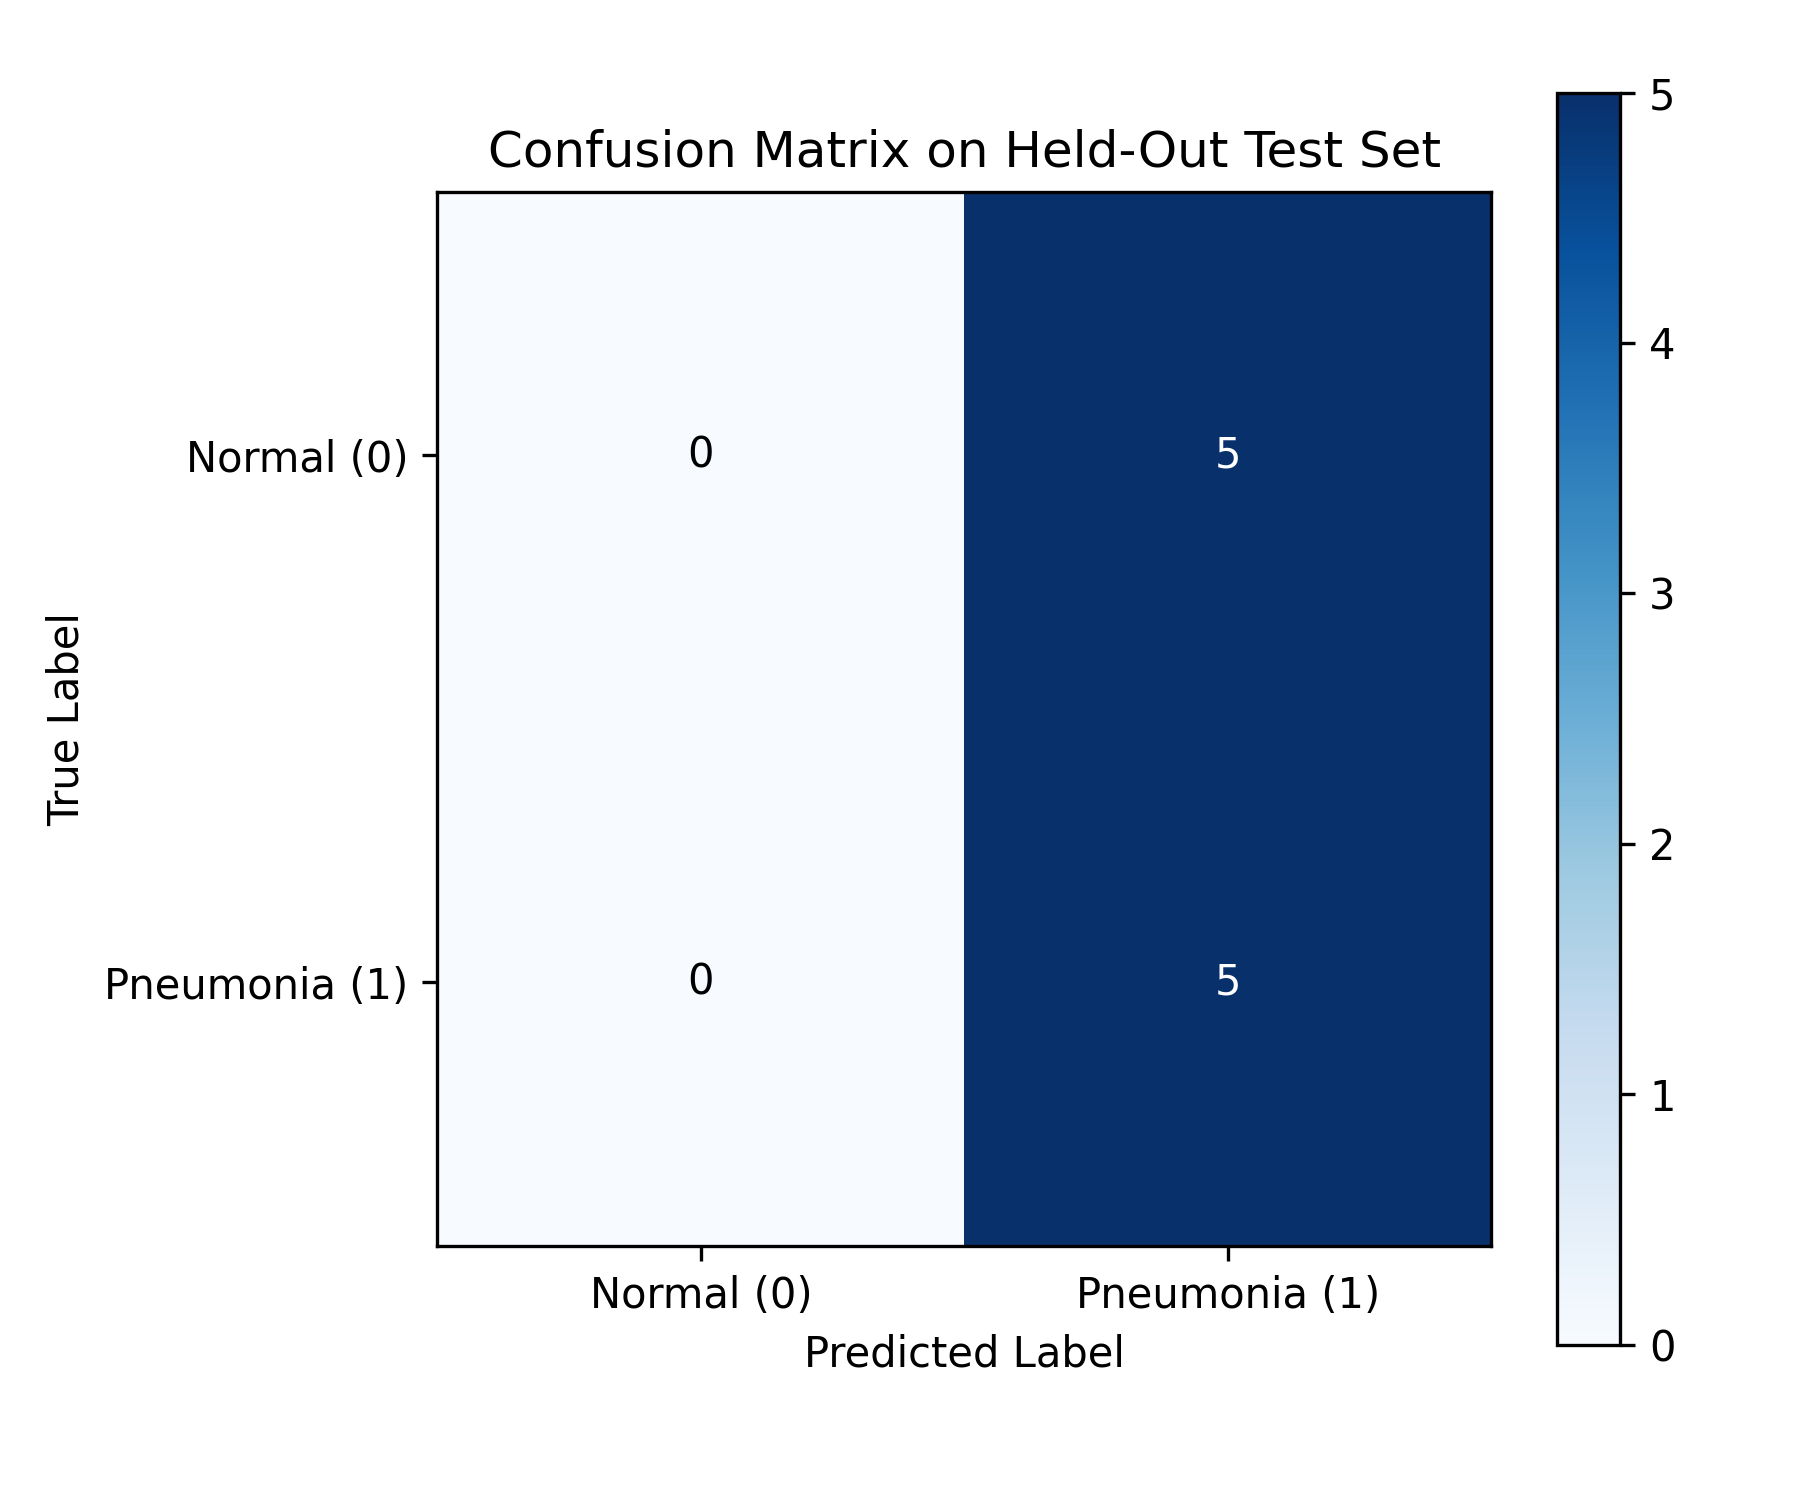


--- ROC Curve ---


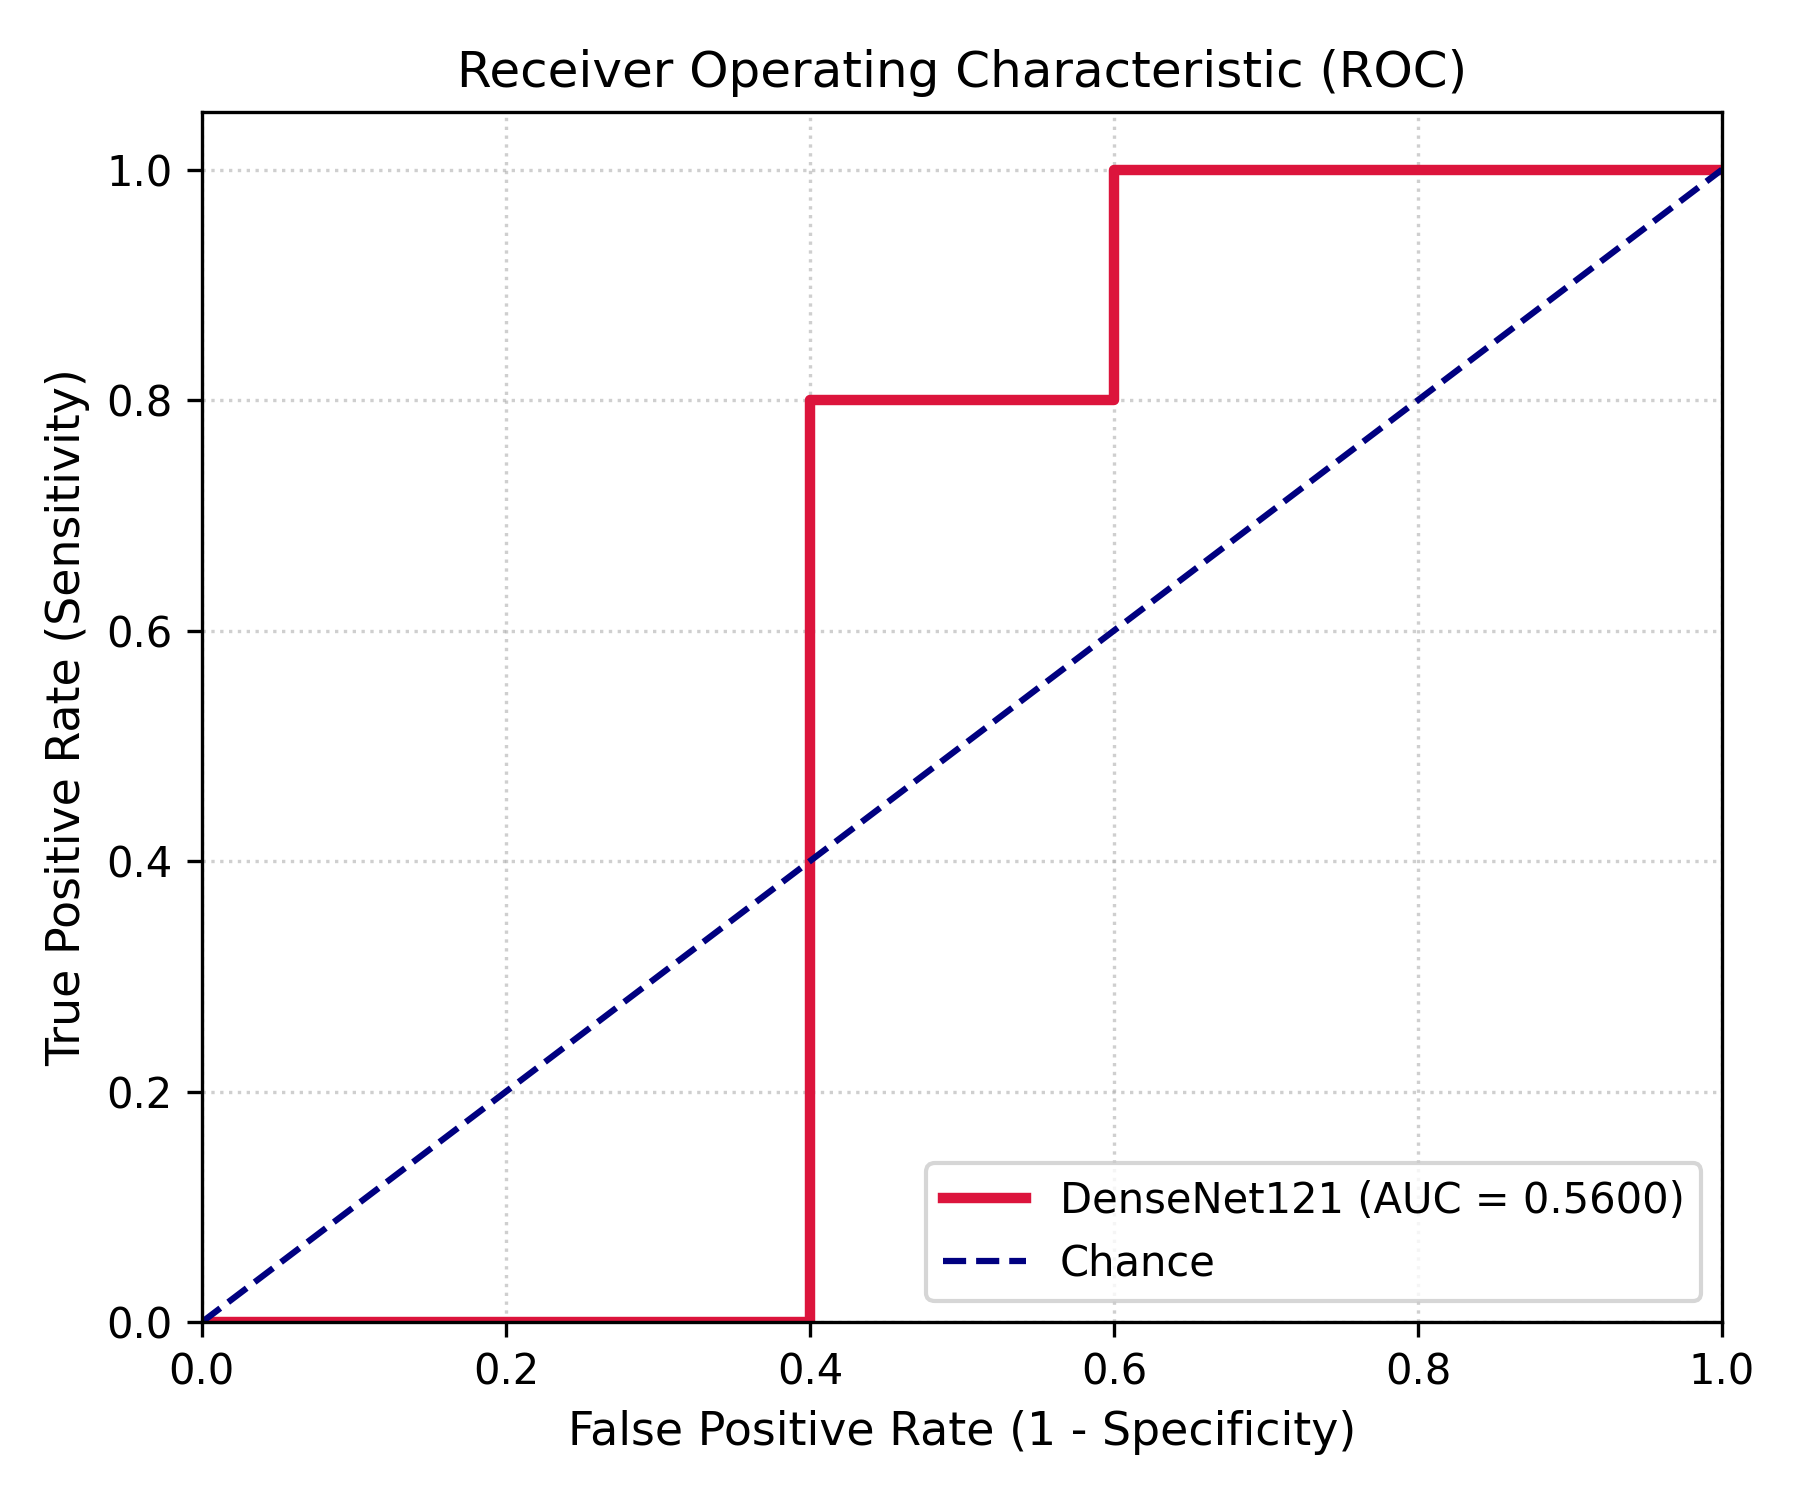

In [30]:
import subprocess
import json
import os
from IPython.display import Image, display

# Configure the environment to allow weights loading in PyTorch 2.6+ and set Python Path
env = os.environ.copy()
env["TORCH_FORCE_WEIGHTS_ONLY_LOAD"] = "0"
# Add rc and rc/src to the python path so imports resolve correctly
repo_root = "/content/Pneumonia_Detection_Localization"
env["PYTHONPATH"] = f"{repo_root}:{repo_root}/rc:{repo_root}/rc/src:" + env.get("PYTHONPATH", "")

print("=== 1. Starting Step 5: Training (1 Epoch) ===")
train_cmd = [
    "python", "rc/src/train.py",
    "--train_csv", "/content/drive/MyDrive/Pneumonia_Project/metadata/train.csv",
    "--val_csv", "/content/drive/MyDrive/Pneumonia_Project/metadata/val.csv",
    "--img_dir", "/content/rsna_train_images/stage_2_train_images/",
    "--checkpoint_dir", "/content/drive/MyDrive/Pneumonia_Project/checkpoints",
    "--epochs", "1",
    "--batch_size", "16",
    "--lr", "0.0001",
    "--num_workers", "2"
]
train_res = subprocess.run(train_cmd, capture_output=True, text=True, env=env)
print(train_res.stdout)
if train_res.returncode != 0:
    print("Training failed with error:")
    print(train_res.stderr)
else:
    print("=== Training Completed Successfully! ===\n")

    print("=== 2. Starting Step 6: Evaluation ===")
    # Use a small wrapper to disable weights_only on torch.load dynamically within the python subprocess
    eval_cmd = [
        "python", "-c",
        "import torch\n"
        "import numpy\n"
        "import sys\n"
        "try:\n"
        "    torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])\n"
        "except:\n"
        "    pass\n"
        "orig_load = torch.load\n"
        "torch.load = lambda *args, **kwargs: orig_load(*args, **{**kwargs, 'weights_only': False})\n"
        "import rc.src.evaluate as evaluate\n"
        "sys.argv = ['evaluate.py', "
        "'--test_csv', '/content/drive/MyDrive/Pneumonia_Project/metadata/test.csv', "
        "'--img_dir', '/content/rsna_train_images/stage_2_train_images/', "
        "'--checkpoint', '/content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth', "
        "'--results_dir', '/content/drive/MyDrive/Pneumonia_Project/results', "
        "'--batch_size', '32']\n"
        "evaluate.evaluate()"
    ]
    eval_res = subprocess.run(eval_cmd, capture_output=True, text=True, env=env)
    print(eval_res.stdout)
    if eval_res.returncode != 0:
        print("Evaluation failed with error:")
        print(eval_res.stderr)
    else:
        print("=== Evaluation Completed Successfully! ===\n")

        print("=== 3. Starting Step 7: Displaying Metrics & Plots ===")
        results_dir = '/content/drive/MyDrive/Pneumonia_Project/results'
        with open(f'{results_dir}/test_metrics.json', 'r') as f:
            metrics = json.load(f)

        print('='*40)
        print('      HELD-OUT TEST RESULTS')
        print('='*40)
        for k, v in metrics.items():
            if k != 'confusion_matrix':
                print(f'{k:15s}: {v:.4f}')
        print('='*40)

        print('\n--- Confusion Matrix ---')
        if os.path.exists(f'{results_dir}/confusion_matrix.png'):
            display(Image(filename=f'{results_dir}/confusion_matrix.png'))
        else:
            print("Confusion matrix plot not found.")

        print('\n--- ROC Curve ---')
        if os.path.exists(f'{results_dir}/roc_curve.png'):
            display(Image(filename=f'{results_dir}/roc_curve.png'))
        else:
            print("ROC curve plot not found.")

### Step 5b: Confirm Saved Checkpoint and Training Logs
Verify that  is saved on Google Drive, confirm its saved epoch and validation AUC, and inspect the final 15-epoch training logs before touching the test set.

In [ ]:
# 1. Verify saved best_model.pth checkpoint
!python rc/src/verify_checkpoint.py \n    --checkpoint '/content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth'

# 2. Display the full training logs across all 15 epochs
with open('/content/drive/MyDrive/Pneumonia_Project/checkpoints/training_logs.txt', 'r') as f:
    print(f.read())

### Step 6: Evaluate Once on Held-out `test.csv`
Evaluates `best_model.pth` on the test set and calculates Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix, and ROC Curve.

In [12]:
!python rc/src/evaluate.py \
    --test_csv '/content/drive/MyDrive/Pneumonia_Project/metadata/test.csv' \
    --img_dir '/content/rsna_train_images/stage_2_train_images/' \
    --checkpoint '/content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth' \
    --results_dir '/content/drive/MyDrive/Pneumonia_Project/results' \
    --batch_size 32

[Member 2 Evaluation] Device: cuda
Traceback (most recent call last):
  File "/content/Pneumonia_Detection_Localization/rc/src/evaluate.py", line 209, in <module>
    evaluate()
    ~~~~~~~~^^
  File "/content/Pneumonia_Detection_Localization/rc/src/evaluate.py", line 122, in evaluate
    raise FileNotFoundError(f"Checkpoint not found at: {args.checkpoint}")
FileNotFoundError: Checkpoint not found at: /content/drive/MyDrive/Pneumonia_Project/checkpoints/best_model.pth


### Step 7: Display Test Metrics & Plots
Review the generated evaluation artifacts saved in Google Drive.

      HELD-OUT TEST RESULTS
accuracy       : 0.5000
precision      : 0.5000
recall         : 1.0000
f1_score       : 0.6667
roc_auc        : 0.5600

--- Confusion Matrix ---


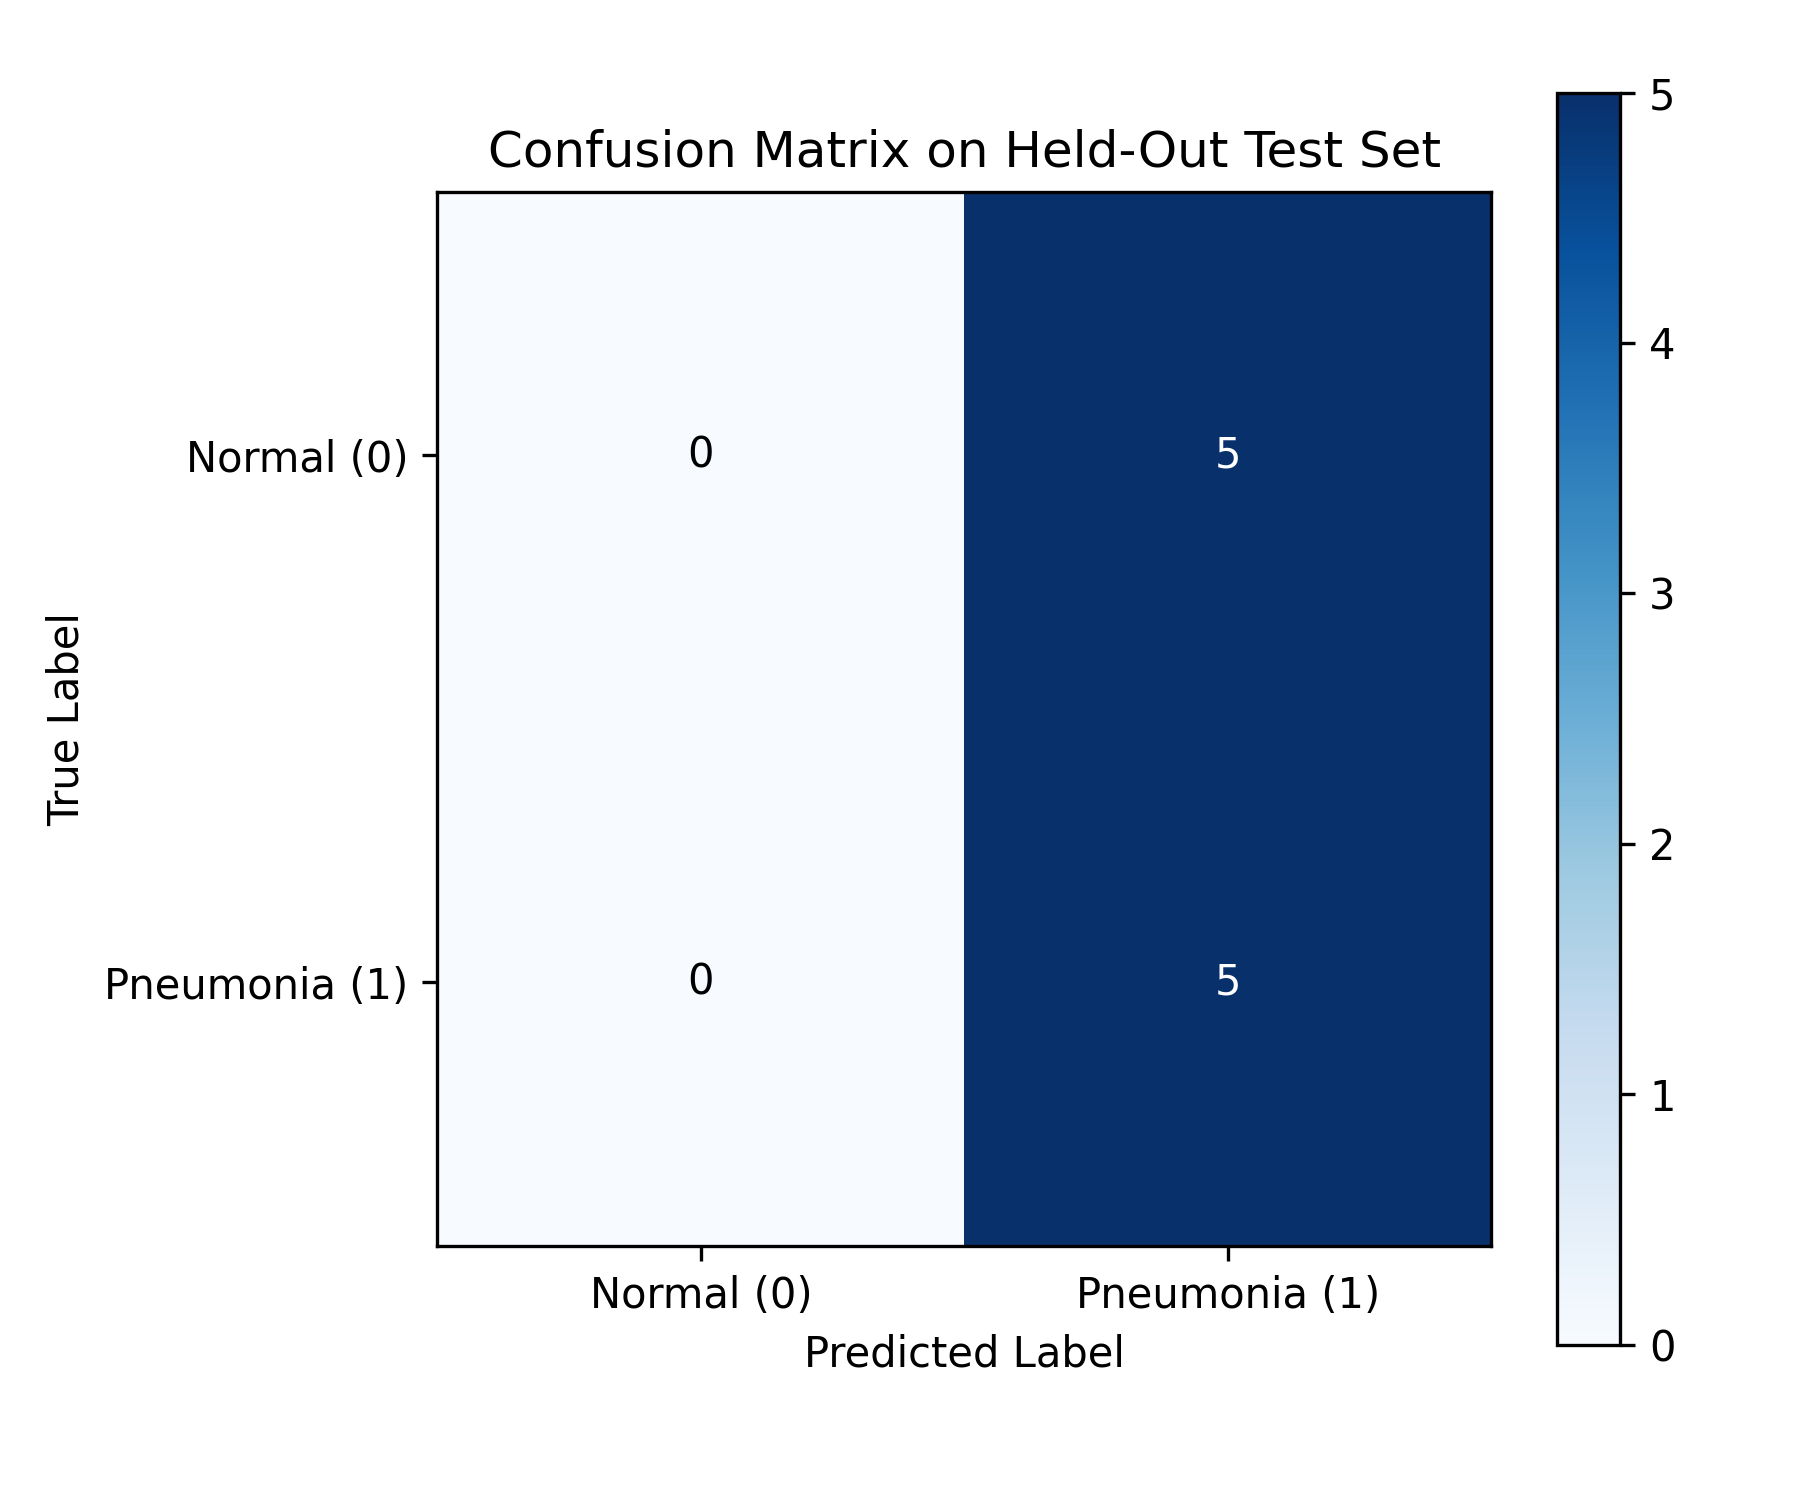


--- ROC Curve ---


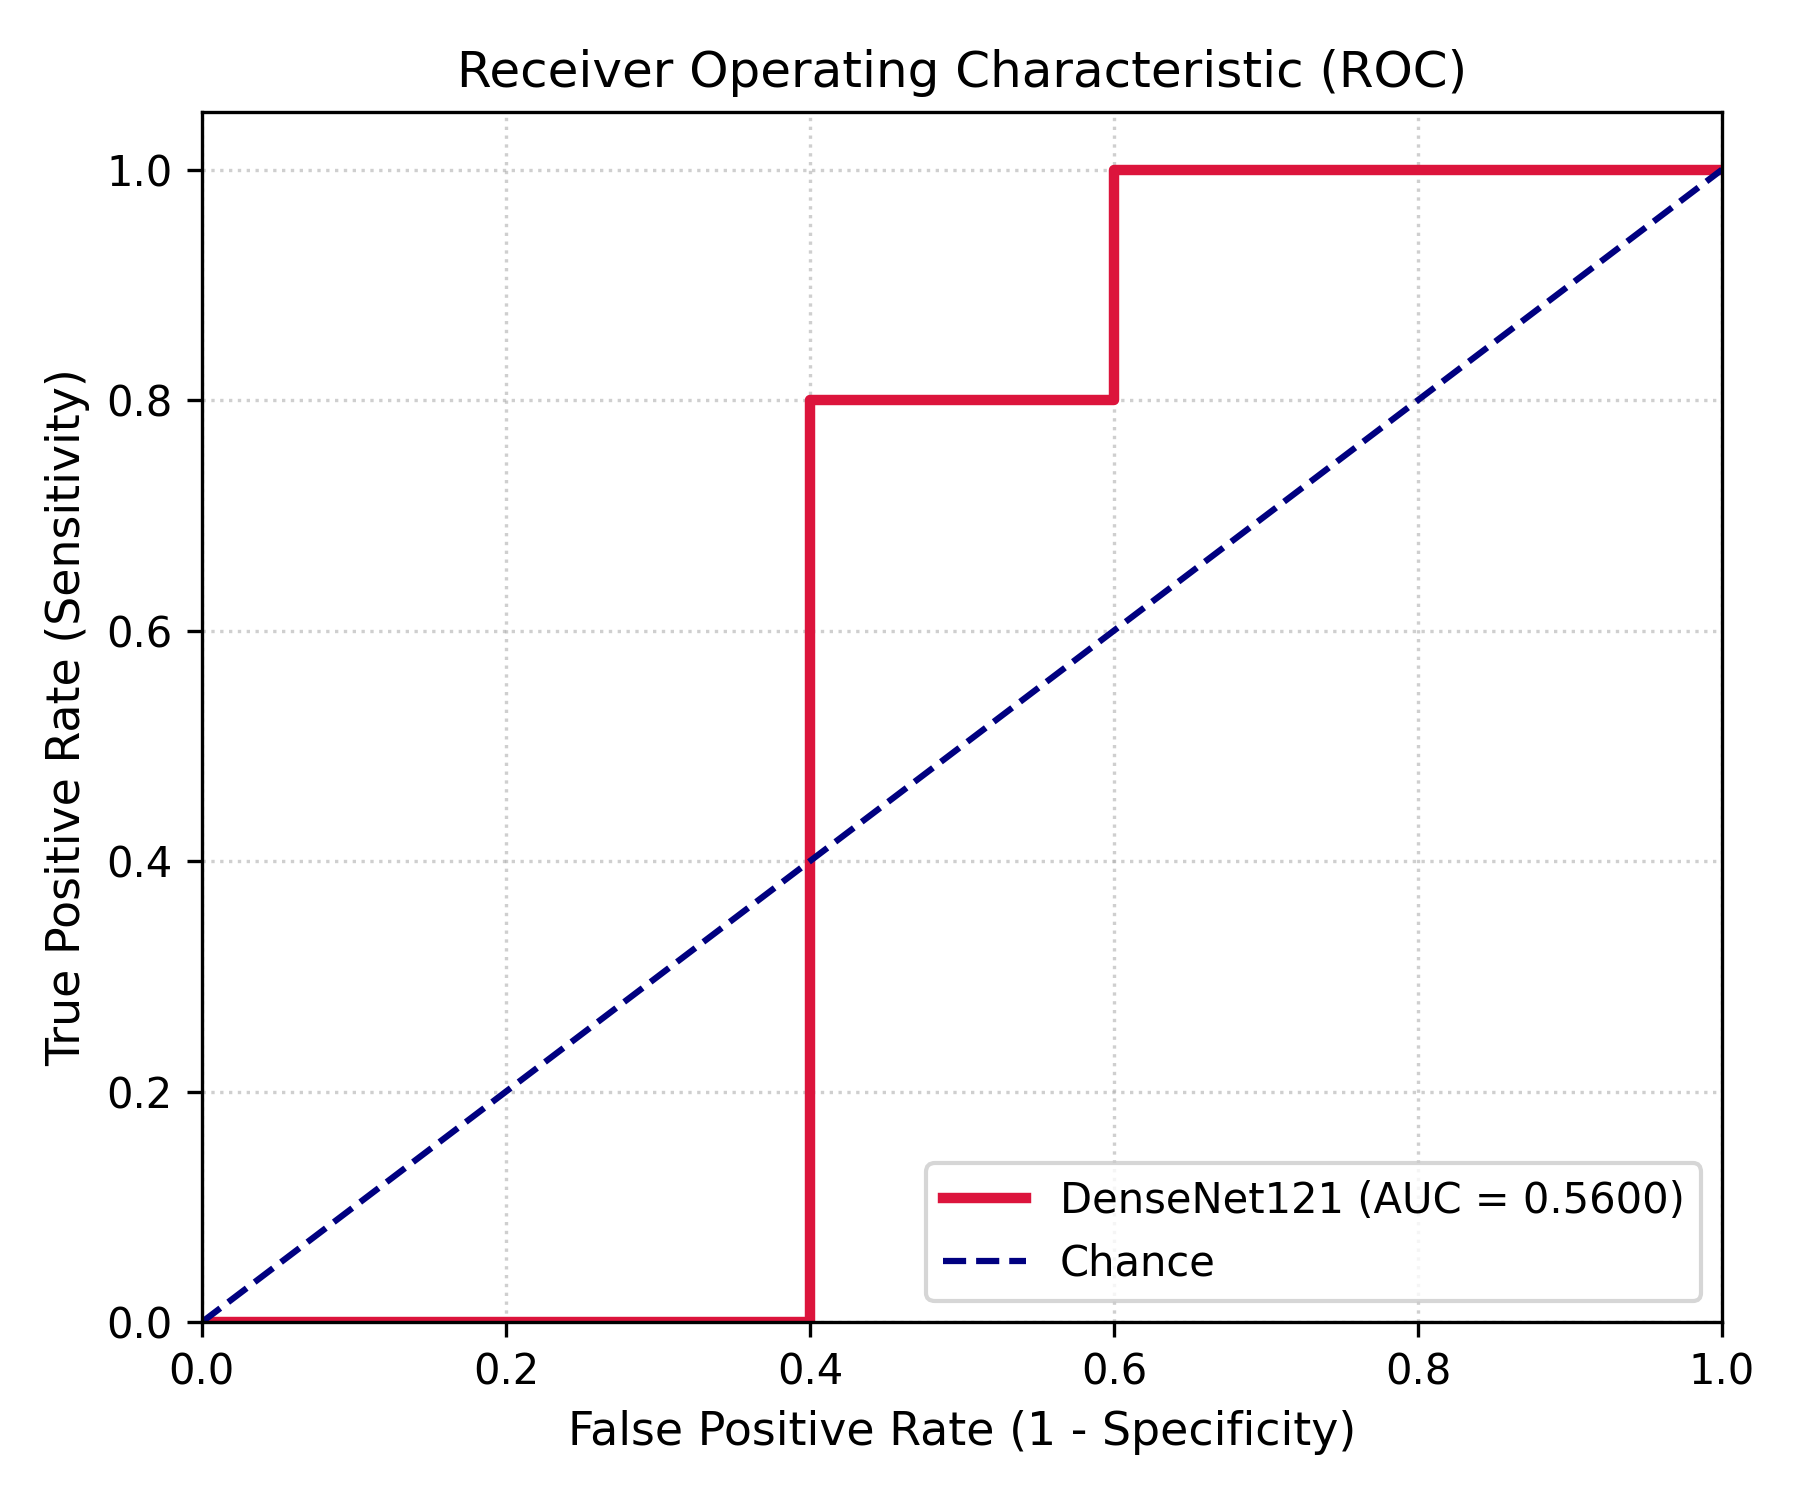

In [31]:
import json
import os
from IPython.display import Image, display

results_dir = '/content/drive/MyDrive/Pneumonia_Project/results'
metrics_path = os.path.join(results_dir, 'test_metrics.json')

if not os.path.exists(metrics_path):
    print(f"Error: Results file not found at {metrics_path}.")
    print("Please ensure you run the unified pipeline in cell ee8a4a45 first.")
else:
    with open(metrics_path, 'r') as f:
        metrics = json.load(f)

    print('='*40)
    print('      HELD-OUT TEST RESULTS')
    print('='*40)
    for k, v in metrics.items():
        if k != 'confusion_matrix':
            print(f'{k:15s}: {v:.4f}')
    print('='*40)

    print('\n--- Confusion Matrix ---')
    cm_path = os.path.join(results_dir, 'confusion_matrix.png')
    if os.path.exists(cm_path):
        display(Image(filename=cm_path))
    else:
        print("Confusion matrix image not found.")

    print('\n--- ROC Curve ---')
    roc_path = os.path.join(results_dir, 'roc_curve.png')
    if os.path.exists(roc_path):
        display(Image(filename=roc_path))
    else:
        print("ROC curve image not found.")